In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, zscore

In [2]:

df = pd.read_csv("train.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:

missing_percent = df.isnull().sum() / len(df) * 100

missing_percent = missing_percent[missing_percent > 0]
missing_percent.sort_values(ascending=False)

PoolQC          99.520548
MiscFeature     96.301370
Alley           93.767123
Fence           80.753425
MasVnrType      59.726027
FireplaceQu     47.260274
LotFrontage     17.739726
GarageType       5.547945
GarageYrBlt      5.547945
GarageFinish     5.547945
GarageQual       5.547945
GarageCond       5.547945
BsmtFinType2     2.602740
BsmtExposure     2.602740
BsmtFinType1     2.534247
BsmtCond         2.534247
BsmtQual         2.534247
MasVnrArea       0.547945
Electrical       0.068493
dtype: float64

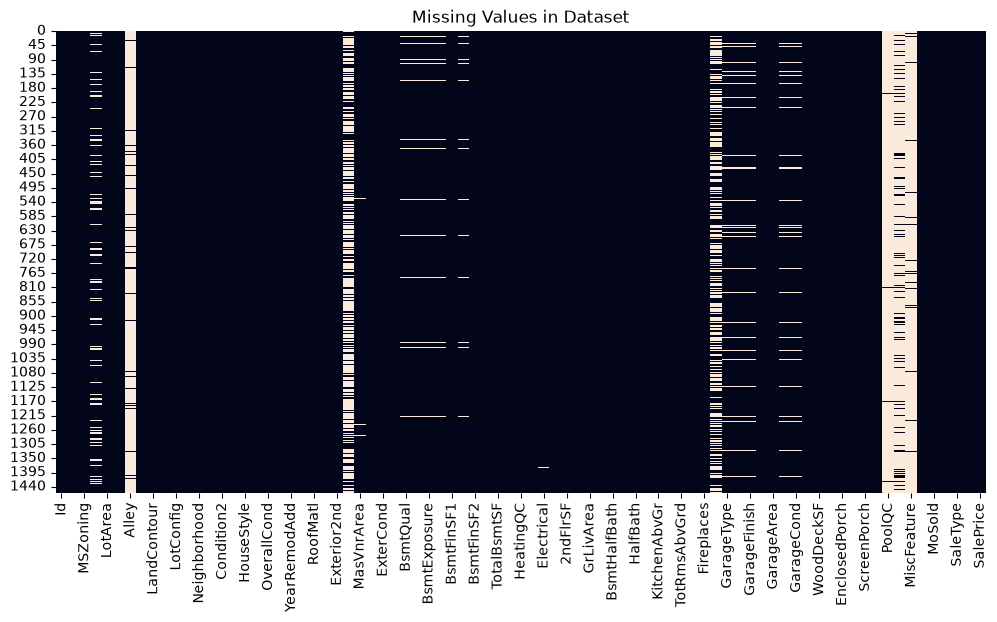

In [4]:

plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values in Dataset")
plt.show()

In [5]:

num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="object").columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [6]:

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

outliers = (
    (df[num_cols] < (Q1 - 1.5 * IQR)) |
    (df[num_cols] > (Q3 + 1.5 * IQR))
).sum()

print(outliers.sort_values(ascending=False))

EnclosedPorch    208
BsmtFinSF2       167
OverallCond      125
ScreenPorch      116
LotFrontage      106
MSSubClass       103
MasVnrArea        98
BsmtHalfBath      82
OpenPorchSF       77
LotArea           69
KitchenAbvGr      68
TotalBsmtSF       61
SalePrice         61
MiscVal           52
BedroomAbvGr      35
WoodDeckSF        32
GrLivArea         31
TotRmsAbvGrd      30
BsmtUnfSF         29
LowQualFinSF      26
3SsnPorch         24
GarageArea        21
1stFlrSF          20
PoolArea           7
BsmtFinSF1         7
YearBuilt          7
Fireplaces         5
GarageCars         5
2ndFlrSF           2
OverallQual        2
GarageYrBlt        1
BsmtFullBath       1
MoSold             0
YrSold             0
Id                 0
HalfBath           0
YearRemodAdd       0
FullBath           0
dtype: int64


In [7]:

z_scores = np.abs(zscore(df[num_cols], nan_policy="omit"))

outliers_z = (z_scores > 3).sum(axis=0)

print(pd.Series(outliers_z, index=num_cols).sort_values(ascending=False))

BsmtHalfBath     82
KitchenAbvGr     68
ScreenPorch      55
EnclosedPorch    51
BsmtFinSF2       50
MasVnrArea       32
MSSubClass       30
OverallCond      28
OpenPorchSF      27
3SsnPorch        23
SalePrice        22
WoodDeckSF       22
LowQualFinSF     20
GrLivArea        16
BsmtFullBath     16
LotFrontage      16
BedroomAbvGr     14
LotArea          13
HalfBath         12
TotRmsAbvGrd     12
1stFlrSF         12
BsmtUnfSF        11
TotalBsmtSF      10
MiscVal           8
PoolArea          7
GarageArea        7
YearBuilt         6
BsmtFinSF1        6
Fireplaces        5
2ndFlrSF          4
OverallQual       2
GarageYrBlt       2
YrSold            0
MoSold            0
Id                0
GarageCars        0
YearRemodAdd      0
FullBath          0
dtype: int32


In [8]:

def cap_outliers(column):
    lower = column.quantile(0.01)
    upper = column.quantile(0.99)
    return column.clip(lower, upper)

for col in num_cols:
    df[col] = cap_outliers(df[col])

print("Outlier treatment completed.")

Outlier treatment completed.


In [9]:

df["SalePrice"] = np.log1p(df["SalePrice"])

print(df["SalePrice"].head())

0    12.247699
1    12.109016
2    12.317171
3    11.849405
4    12.429220
Name: SalePrice, dtype: float64


In [10]:

df["TotalArea"] = (
    df["TotalBsmtSF"] +
    df["1stFlrSF"] +
    df["2ndFlrSF"]
)

print(df[["TotalBsmtSF", "1stFlrSF",
          "2ndFlrSF", "TotalArea"]].head())

   TotalBsmtSF  1stFlrSF  2ndFlrSF  TotalArea
0        856.0     856.0     854.0     2566.0
1       1262.0    1262.0       0.0     2524.0
2        920.0     920.0     866.0     2706.0
3        756.0     961.0     756.0     2473.0
4       1145.0    1145.0    1053.0     3343.0


In [11]:

corr_matrix = df.select_dtypes(include=np.number).corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

to_drop = [
    column for column in upper.columns
    if any(upper[column] > 0.9)
]

print("Features to remove:", to_drop)

df.drop(columns=to_drop, inplace=True)

Features to remove: []


In [12]:

df.to_csv("cleaned_house_prices.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (1460, 82)


In [13]:

df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice,TotalArea
count,1460.00000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.0,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.50000,56.897260,69.459692,10063.006575,6.104110,5.580137,1971.413493,1984.861644,100.613836,438.530240,...,45.825548,21.434760,2.520548,14.326541,0.0,19.482192,6.321918,2007.815753,12.024240,2553.927021
std,421.34343,42.300571,19.581352,5062.299090,1.369444,1.098826,29.806332,20.640499,167.724777,429.049203,...,61.985174,58.382129,19.932690,51.369279,0.0,104.884363,2.703626,1.328095,0.386349,755.344437
min,15.59000,20.000000,21.000000,1680.000000,3.000000,3.000000,1899.180000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,1.000000,2006.000000,11.031933,520.000000
25%,365.75000,20.000000,60.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,5.000000,2007.000000,11.775105,2009.500000
50%,730.50000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,25.000000,0.000000,0.000000,0.000000,0.0,0.000000,6.000000,2008.000000,12.001512,2474.000000
75%,1095.25000,70.000000,79.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,164.250000,712.250000,...,68.000000,0.000000,0.000000,0.000000,0.0,0.000000,8.000000,2009.000000,12.273736,3004.000000
max,1445.41000,190.000000,137.410000,37567.640000,10.000000,9.000000,2009.000000,2009.000000,791.280000,1572.410000,...,285.820000,261.050000,168.000000,268.050000,0.0,700.000000,12.000000,2010.000000,13.000349,5793.430000
